In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_regression, f_classif
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,make_union
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold, GridSearchCV, learning_curve
from sklearn.metrics import make_scorer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor, RadiusNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("train.csv")
df.head(2)

,ID,date,device,site_latitude,site_longitude,humidity,temp_mean,SulphurDioxide_SO2_column_number_density,SulphurDioxide_SO2_column_number_density_amf,SulphurDioxide_SO2_slant_column_number_density,...,Cloud_cloud_top_height,Cloud_cloud_base_pressure,Cloud_cloud_base_height,Cloud_cloud_optical_depth,Cloud_surface_albedo,Cloud_sensor_azimuth_angle,Cloud_sensor_zenith_angle,Cloud_solar_azimuth_angle,Cloud_solar_zenith_angle,pm2_5
0,ID_JBYXJEUZ8X,2020-03-18,ANQ16PZJ,0.353465,32.560322,0.846844,22.038542,-0.000138,1.042629,-0.000143,...,4181.792969,69589.453125,3181.793457,7.799846,0.278111,76.618553,9.970293,-93.110069,19.214193,63.853333
1,ID_PEJJNLBUPR,2019-10-13,AB6051M4,0.390741,32.582257,0.874493,21.545833,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.507083


In [22]:
def create_features(df):
    for i in df.select_dtypes(["float","int"]).columns:
        df[f"mean_{i}_per_site_"]=df.groupby(["site"])[f"{i}"].transform(np.mean)
        df[f"mean_{i}_per_site_per_day"]=df.groupby(["site","day"])[f"{i}"].transform(np.mean)
        df[f"mean_{i}_per_site_per_week"]=df.groupby(["site","week"])[f"{i}"].transform(np.mean)
        df[f"mean_{i}_per_site_per_dow"]=df.groupby(["site","day_of_week"])[f"{i}"].transform(np.mean)
        df[f"mean_{i}_per_site_per_month"]=df.groupby(["site","month"])[f"{i}"].transform(np.mean)
        df[f"mean_{i}_per_day"]=df.groupby(["day"])[f"{i}"].transform(np.mean)
        df[f"mean_{i}_per_week"]=df.groupby(["week"])[f"{i}"].transform(np.mean)
        df[f"mean_{i}_per_dow"]=df.groupby(["day_of_week"])[f"{i}"].transform(np.mean)
        df[f"mean_{i}_per_month"]=df.groupby(["month"])[f"{i}"].transform(np.mean)
    return df.drop("site", axis=1)

In [23]:
cor = df.corr().pm2_5
not_used_columns=[cor.index[i] for i,j in enumerate(cor) if np.abs(j)<=0.0]
not_used_columns.extend(["ID", "date", "device", "site_latitude", "site_longitude"])

for i in [df.columns[i] for i,j in enumerate(df.isna().sum()*100/df.shape[0]) if j>=50]:
    if i not in not_used_columns:
        not_used_columns.append(i)

# Add DATE FEATURES
df.date=pd.DatetimeIndex(df.date)
#df["year"]=df.date.dt.year
df["month"]=df.date.dt.month.map(str)
df["day"]=df.date.dt.day.map(str)
df['day_of_week']=df.date.dt.dayofweek.map(str)
df["week"]=df.date.dt.isocalendar().week.map(str)
#df["year-month"]=df.year.map(str)+"-"+df.month.map(str)
df["site"]=df.site_latitude.map(str)+"-"+df.site_longitude.map(str)

train_df = df.drop(not_used_columns,axis=1)
train_df.head(2)

,humidity,temp_mean,CarbonMonoxide_CO_column_number_density,CarbonMonoxide_H2O_column_number_density,CarbonMonoxide_cloud_height,CarbonMonoxide_sensor_altitude,CarbonMonoxide_sensor_azimuth_angle,CarbonMonoxide_sensor_zenith_angle,CarbonMonoxide_solar_azimuth_angle,CarbonMonoxide_solar_zenith_angle,...,Cloud_sensor_azimuth_angle,Cloud_sensor_zenith_angle,Cloud_solar_azimuth_angle,Cloud_solar_zenith_angle,pm2_5,month,day,day_of_week,week,site
0,0.846844,22.038542,0.03374,2457.111816,1353.664673,829636.0,70.372986,10.312428,-93.008011,19.194933,...,76.618553,9.970293,-93.110069,19.214193,63.853333,3,18,2,12,0.3534645999999999-32.5603223
1,0.874493,21.545833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,32.507083,10,13,6,41,0.3907412-32.5822574


In [24]:
X=create_features(train_df.drop("pm2_5", axis=1))
y=train_df.pm2_5

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=25)

In [25]:
def make_model(X, estimator):
    quanti_var=list(X.columns[X.dtypes=="float64"])
    quali_var=list(X.columns[X.dtypes=="object"])
    num_pipeline=make_pipeline(SimpleImputer(strategy="median"), PCA(n_components=270))
    cat_pipeline=make_pipeline(OneHotEncoder(handle_unknown='ignore'))
    transformer=make_column_transformer((num_pipeline,quanti_var),(cat_pipeline,quali_var))
    regressor=make_pipeline(transformer, estimator)
    model=TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)

    return model

In [26]:
def custom_metric(y,y_pred):
    Err_=0
    Bias=np.mean(y_pred-y)
    Var=np.mean(y_pred**2) - np.mean(y_pred)**2
    return Bias**2+Var+Err_

In [27]:
ESTIMATORS={
    # 'rf': RandomForestRegressor(),
    # 'ad': AdaBoostRegressor(),
    # 'et': ExtraTreesRegressor(),
    # 'gb': GradientBoostingRegressor(),
    # 'hg': HistGradientBoostingRegressor(),
    # 'kn': KNeighborsRegressor(),
    # 'rn': RadiusNeighborsRegressor(),
    # 'lr': LinearRegression(),
    # 'svm': SVR(),
    # 'lgb': LGBMRegressor()
}
scorer=make_scorer(mean_absolute_error)
custom_scorer=make_scorer(custom_metric, greater_is_better=False)
cv=KFold(n_splits=8)

In [28]:
estimator=LGBMRegressor(boosting_type='gbdt', objective='regression', num_leaves=1200,
                        learning_rate=0.17, n_estimators=380, max_depth=9,
                        metric='mae', reg_lambda=0.9, use_missing=True)
model=make_model(X_train, estimator)

In [21]:
# hyper_params = {
#     'regressor__columntransformer__pipeline-1__pca__n_components': range(0,300,10),
# }
# grid=GridSearchCV(model,hyper_params,scoring=custom_scorer,cv=8,n_jobs=-1,return_train_score=True,verbose=1)
# grid.fit(X_train, y_train)

In [13]:
def evaluation(model):

    N, train_score, val_score = learning_curve(
                                    model, X_train, y_train, cv=8,
                                    scoring=scorer,n_jobs=-1,
                                    train_sizes=np.linspace(0.1,1,5)
                                )
    
    plt.figure(figsize=(12,8))
    plt.plot(N, train_score.mean(axis=1), label='train score')
    plt.plot(N, val_score.mean(axis=1), label="validation score")
    plt.legend()

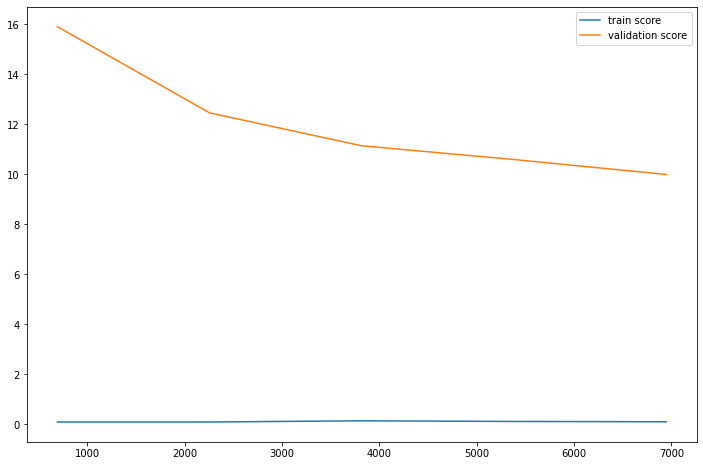

In [14]:
evaluation(model)

In [29]:
model.fit(X_train,y_train)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('columntransformer',
                                                      ColumnTransformer(transformers=[('pipeline-1',
                                                                                       Pipeline(steps=[('simpleimputer',
                                                                                                        SimpleImputer(strategy='median')),
                                                                                                       ('pca',
                                                                                                        PCA(n_components=270))]),
                                                                                       ['humidity',
                                                                                        'temp_mean',
                                           

In [30]:
y_pred=model.predict(X_test)
print(f"SCORE: {mean_absolute_error(y_test,y_pred)}")
print(f"SCORE: {custom_metric(y_test,y_pred)}")

SCORE: 10.704498326238818
SCORE: 410.2763495373933


In [31]:
test_df = pd.read_csv("test.csv") 
submit = pd.read_csv("SampleSubmission.csv")

In [32]:
test_df.date=pd.DatetimeIndex(test_df.date)
#test_df["year"]=test_df.date.dt.year
test_df["month"]=test_df.date.dt.month.map(str)
test_df["day"]=test_df.date.dt.day.map(str)
test_df['day_of_week']=test_df.date.dt.dayofweek.map(str)
test_df["week"]=test_df.date.dt.isocalendar().week.map(str)
#test_df["year-month"]=test_df.year.map(str)+"-"+test_df.month.map(str)
test_df["site"]=test_df.site_latitude.map(str)+"-"+test_df.site_longitude.map(str)

cols = [t for t in test_df.columns if t not in train_df.columns]
test_df = create_features(test_df.drop(cols, axis=1))
# test_df.fillna(0,inplace=True)

In [33]:
pred=model.predict(test_df)
submit.pm2_5=pred
submit.head()

,ID,pm2_5
0,ID_UOH62J0XHX,51.895225
1,ID_4OPWSB0UHJ,54.148580
2,ID_3SLMNNG1Z3,38.426751
3,ID_MFUHTXYPM4,59.274721
4,ID_TY1DAND8ZP,55.479240


In [20]:
submit.to_csv("submit_51.csv", index=False)